# 🏠 Analyse Complète — California Housing Dataset

**Objectif :** Répondre aux questions suivantes :
1. Statistiques descriptives & distribution des variables
2. Corrélations entre les features et le prix médian (`MedHouseVal`)
3. Distribution géographique des prix (carte)
4. Analyse des outliers
5. Modélisation MLP PyTorch avec évaluation complète

---
| Variable | Description |
|---|---|
| `MedInc` | Revenu médian des ménages (en dizaines de milliers $) |
| `HouseAge` | Âge médian des maisons |
| `AveRooms` | Nombre moyen de pièces par logement |
| `AveBedrms` | Nombre moyen de chambres par logement |
| `Population` | Population du bloc |
| `AveOccup` | Nombre moyen d'occupants par logement |
| `Latitude` | Latitude du bloc |
| `Longitude` | Longitude du bloc |
| `MedHouseVal` | **Cible** — Valeur médiane des maisons (en centaines de milliers $) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

## 1. Chargement & Statistiques Descriptives

In [2]:
df = pd.read_csv('california_housing.csv')
df.describe().T.style.background_gradient(cmap='Blues', subset=['mean', 'std', '50%'])

,count,mean,std,min,25%,50%,75%,max
MedInc,20641.000000,3.870682,1.899768,0.499900,2.563700,3.534900,4.743100,15.000100
HouseAge,20640.000000,28.640746,12.586691,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20642.000000,5.428920,2.474068,0.846154,4.440652,5.228973,6.052319,141.909091
AveBedrms,20642.000000,1.096668,0.473889,0.333333,1.006067,1.048780,1.099520,34.066667
Population,20641.000000,1425.459861,1132.442718,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20641.000000,3.070674,10.385797,0.692308,2.429787,2.818182,3.282258,1243.333333
Latitude,20641.000000,35.631966,2.135953,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20641.000000,-119.569832,2.003567,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20642.000000,2.068553,1.153924,0.149990,1.196000,1.797000,2.647750,5.000010


## 2. Distributions des Variables

Histogrammes avec estimation KDE — utile pour détecter les asymétries et les valeurs aberrantes.

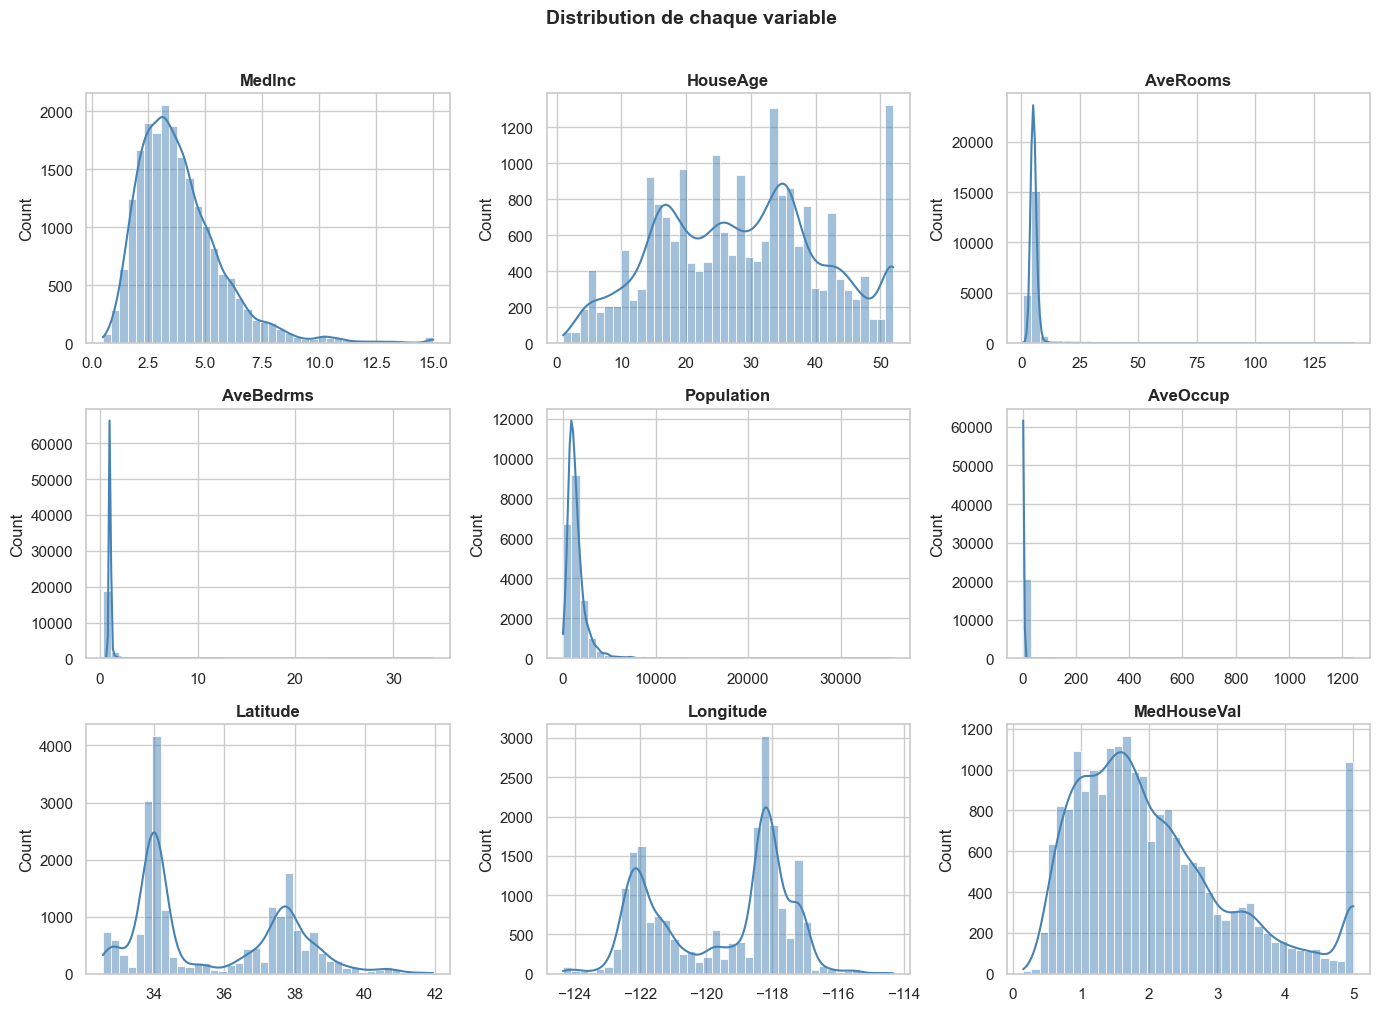

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue', bins=40)
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('')
plt.suptitle('Distribution de chaque variable', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 3. Matrice de Corrélation

> `MedInc` est la variable la plus corrélée avec le prix — revenu médian ≈ meilleur prédicteur.

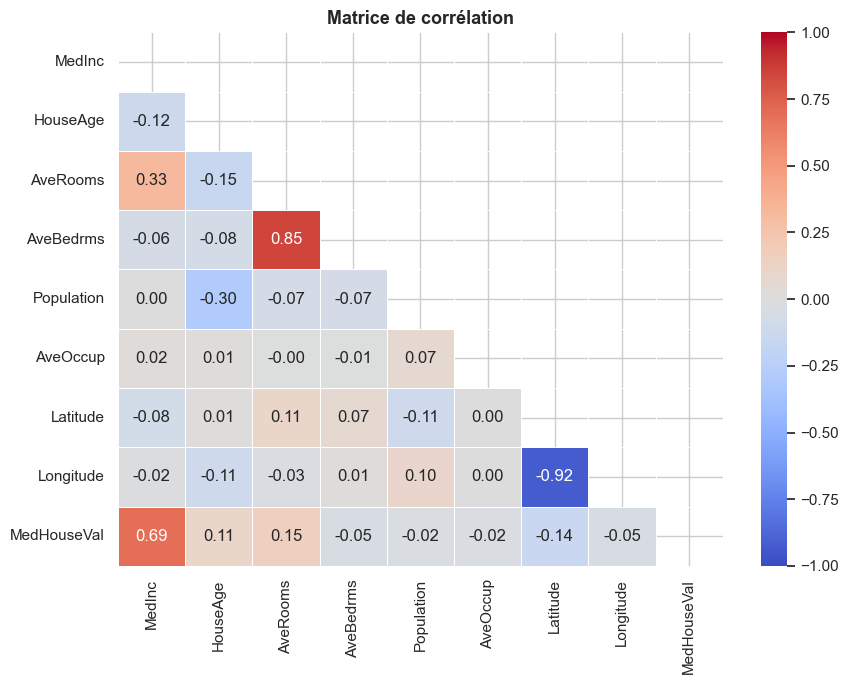

In [4]:
plt.figure(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matrice de corrélation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Corrélation avec la Cible (`MedHouseVal`)

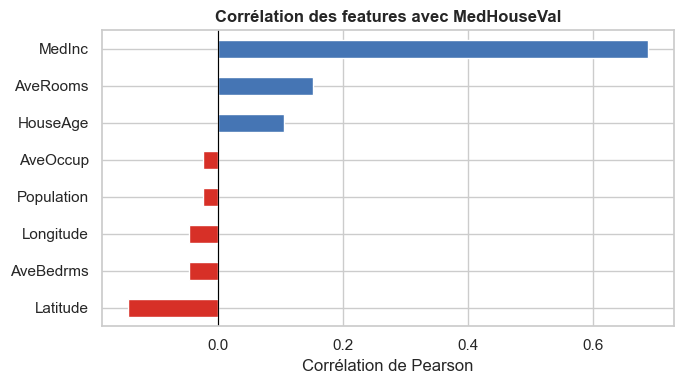

In [5]:
target_corr = corr['MedHouseVal'].drop('MedHouseVal').sort_values()
colors = ['#d73027' if v < 0 else '#4575b4' for v in target_corr]

plt.figure(figsize=(7, 4))
target_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Corrélation des features avec MedHouseVal', fontweight='bold')
plt.xlabel('Corrélation de Pearson')
plt.tight_layout()
plt.show()

## 5. Carte Géographique des Prix

Chaque point = un bloc résidentiel. La couleur encode le prix médian.  
On distingue clairement les zones chères : **San Francisco**, **Los Angeles**, **San Diego**.

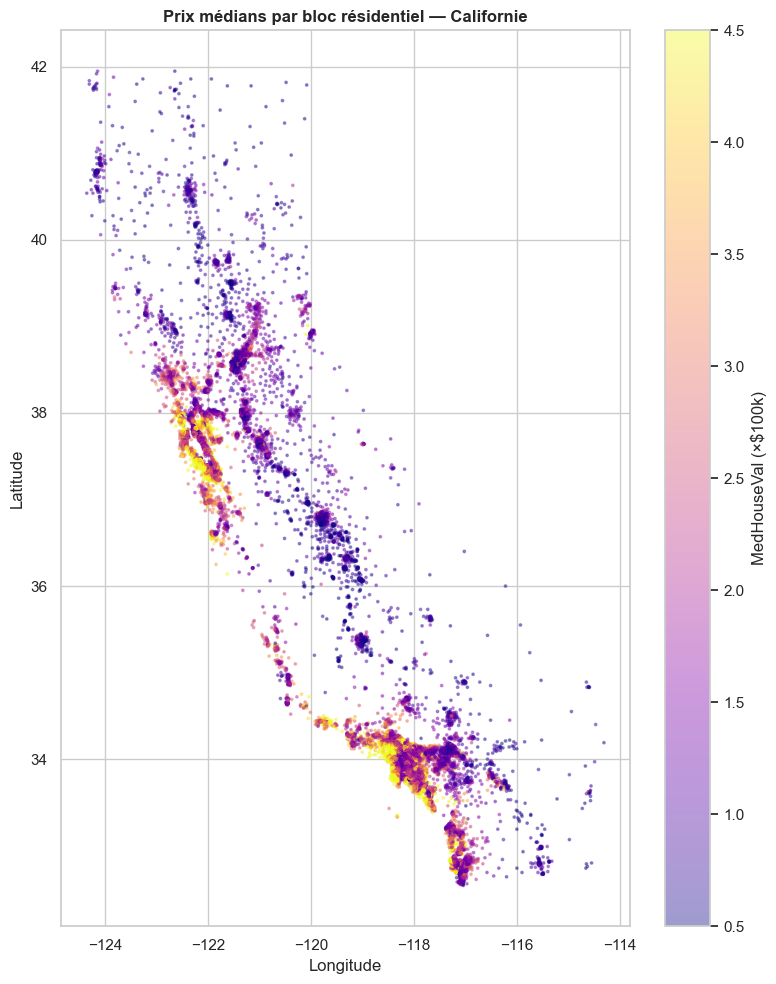

In [6]:
plt.figure(figsize=(8, 10))
sc = plt.scatter(
    df['Longitude'], df['Latitude'],
    c=df['MedHouseVal'], cmap='plasma',
    alpha=0.4, s=3, vmin=0.5, vmax=4.5
)
plt.colorbar(sc, label='MedHouseVal (×$100k)')
plt.xlabel('Longitude') ; plt.ylabel('Latitude')
plt.title('Prix médians par bloc résidentiel — Californie', fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Revenu vs Prix

Relation quasi-linéaire entre `MedInc` et `MedHouseVal` — confirme la corrélation forte (~0.69).  
On observe le **plafonnement à 5.0** (valeurs fictives à supprimer au nettoyage).

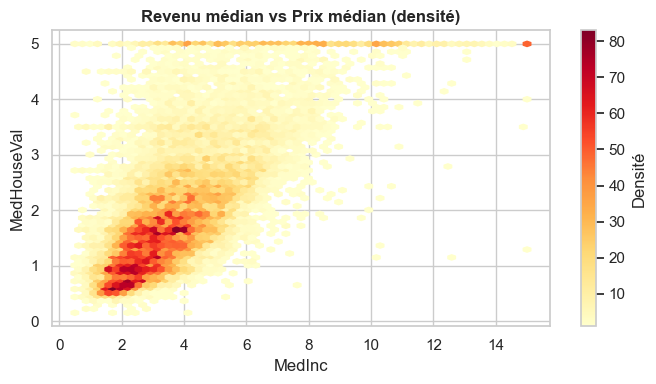

In [7]:
plt.figure(figsize=(7, 4))
plt.hexbin(df['MedInc'], df['MedHouseVal'], gridsize=60, cmap='YlOrRd', mincnt=1)
plt.colorbar(label='Densité')
plt.xlabel('MedInc') ; plt.ylabel('MedHouseVal')
plt.title('Revenu médian vs Prix médian (densité)', fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Division Train / Test

> ⚠️ La division se fait **avant** tout nettoyage et toute transformation.  
> Cela évite le **data leakage** : les statistiques (médiane, IQR, μ, σ) ne sont calculées que sur le train, puis appliquées au test.

| Étape | Sur train | Sur test |
|---|---|---|
| Valeurs manquantes | `fillna(médiane_train)` | `fillna(médiane_train)` |
| Doublons | `drop_duplicates()` | — |
| Outliers | filtrés (IQR ±1.5) | conservés tels quels |
| Normalisation | `fit_transform` | `transform` |

In [ ]:
from sklearn.model_selection import train_test_split

# Division stratifiée sur la variable cible (80% train / 20% test)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_df = train_df.copy()
test_df  = test_df.copy()

f"Train: {train_df.shape[0]:,} lignes | Test: {test_df.shape[0]:,} lignes | Features: {train_df.shape[1]}"

'19,525 échantillons — Train: 15,620 | Test: 3,905'

## 8. Nettoyage

### 8.1 Valeurs Manquantes

On détecte les `NaN` sur le jeu train, puis on impute par la **médiane du train** (robuste aux outliers).  
Le même vecteur de médianes est appliqué au test — aucune information du test n'est utilisée.

In [ ]:
# Audit des valeurs manquantes
missing = train_df.isnull().sum()
print("=== Valeurs manquantes (train) ===")
if missing.sum() == 0:
    print("✓ Aucune valeur manquante")
else:
    display(missing[missing > 0].rename('NaN').to_frame())

# Imputation par la médiane du train → même valeurs appliquées au test
train_medians = train_df.median(numeric_only=True)
train_df = train_df.fillna(train_medians)
test_df  = test_df.fillna(train_medians)

'Paramètres entraînables : 44,417'

### 8.2 Doublons

On cherche les lignes identiques dans le train et on les supprime.  
Le test n'est pas modifié (un doublon en production reste une observation valide à prédire).

In [ ]:
n_before = len(train_df)
train_df = train_df.drop_duplicates()
n_removed = n_before - len(train_df)

f"Doublons supprimés : {n_removed} ({'✓ aucun' if n_removed == 0 else n_removed}) → Train: {len(train_df):,} lignes"

KeyboardInterrupt: 

### 8.3 Outliers — Règle de Tukey (±1.5 × IQR)

$$\text{Borne inférieure} = Q_1 - 1.5 \times IQR \qquad \text{Borne supérieure} = Q_3 + 1.5 \times IQR$$

- Les bornes sont calculées sur le **train** et seules les lignes hors bornes du train sont supprimées.
- Le **test** est conservé intégralement (on ne filtre pas des données de production).

In [ ]:
num_cols = train_df.select_dtypes(include='number').columns.tolist()
n_before = len(train_df)

# Calcul des bornes sur train + filtrage
mask = pd.Series(True, index=train_df.index)
bounds = {}
for col in num_cols:
    Q1, Q3 = train_df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    bounds[col] = (lo, hi)
    mask &= train_df[col].between(lo, hi)

train_df = train_df[mask]
n_out = n_before - len(train_df)

# Résumé des bornes
bounds_df = pd.DataFrame(bounds, index=['Borne inf', 'Borne sup']).T
display(bounds_df.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=1))
print(f"\nOutliers supprimés : {n_out:,} ({n_out/n_before*100:.1f}%) → Train: {len(train_df):,} lignes")

## 9. Transformation

### 9.1 Encodage — Label Encoding & One-Hot Encoding

> **Non applicable ici.**  
> Toutes les colonnes du dataset California Housing sont **numériques continues**.  
> Il n'y a aucune variable catégorielle → ni `LabelEncoder` ni `pd.get_dummies` ne sont nécessaires.  
>
> *Si le dataset contenait des colonnes texte (ex. `ocean_proximity`), on aurait utilisé :*  
> - **Label Encoding** pour les ordinales (ex. `petit < moyen < grand`)  
> - **One-Hot Encoding** pour les nominales (ex. `couleur : rouge / bleu / vert`)

In [ ]:
cat_cols = train_df.select_dtypes(include='object').columns.tolist()
f"Colonnes catégorielles : {cat_cols if cat_cols else '[]  → Encodage non utilisé'}"

### 9.2 Normalisation

Deux méthodes courantes :

| Méthode | Formule | Quand l'utiliser |
|---|---|---|
| **Z-score** (StandardScaler) | $z = \dfrac{x - \mu}{\sigma}$ | Distribution approximativement normale, présence d'outliers modérés |
| **Min-Max** (MinMaxScaler) | $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ | Bornes connues, pas d'outliers extrêmes |

→ On utilise ici le **Z-score** : adapté car les features ont des échelles très différentes et le MLP converge mieux avec une variance unitaire.  
Le scaler est **fitté sur train uniquement**, puis appliqué aux deux ensembles.

In [ ]:
from sklearn.preprocessing import StandardScaler

FEATURE_COLS = [c for c in train_df.columns if c != 'MedHouseVal']
TARGET_COL   = 'MedHouseVal'

X_train_raw = train_df[FEATURE_COLS].values
y_train     = train_df[TARGET_COL].values
X_test_raw  = test_df[FEATURE_COLS].values
y_test      = test_df[TARGET_COL].values

# fit sur train → transform sur les deux (Z-score)
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)   # calcule μ, σ sur train
X_test  = scaler.transform(X_test_raw)        # réutilise μ, σ du train

# Vérification : μ ≈ 0 et σ ≈ 1 sur le train après normalisation
stats = pd.DataFrame({'μ train': X_train.mean(axis=0).round(4),
                      'σ train': X_train.std(axis=0).round(4)},
                     index=FEATURE_COLS)
display(stats.style.background_gradient(cmap='Blues', subset=['σ train']))

# Tenseurs PyTorch & DataLoaders
X_tr = torch.tensor(X_train, dtype=torch.float32)
y_tr = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_te = torch.tensor(X_test,  dtype=torch.float32)
y_te = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)
test_loader  = DataLoader(TensorDataset(X_te, y_te), batch_size=64)

## 10. Architecture MLP

```
Input(8)
  └─ Linear(256) → BatchNorm → ReLU → Dropout(0.3)
       └─ Linear(128) → BatchNorm → ReLU → Dropout(0.3)
            └─ Linear(64)  → BatchNorm → ReLU → Dropout(0.2)
                 └─ Linear(1)   ← sortie linéaire (régression)
```

- **BatchNorm** : normalise les activations à chaque couche → stabilise et accélère l'entraînement
- **Dropout** : désactive aléatoirement des neurones → régularisation, réduit le surapprentissage
- **Pas d'activation en sortie** : la cible est une valeur continue (régression)

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128),  nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64),   nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 1)
        )
    def forward(self, x): return self.net(x)

model     = MLP(X_train.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

f"Paramètres entraînables : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}"

## 11. Entraînement — Early Stopping + LR Scheduler

- **Early Stopping** : arrête l'entraînement si la loss de test ne s'améliore pas pendant `PATIENCE` epochs → évite le surapprentissage
- **ReduceLROnPlateau** : divise le learning rate par 2 si pas d'amélioration après 5 epochs → convergence plus fine

In [ ]:
train_losses, test_losses = [], []
best_loss, patience_cnt, PATIENCE = float('inf'), 0, 15
MODEL_PATH = 'mlp_immobilier_best.pth'

for epoch in range(1, 201):
    # --- Phase entraînement ---
    model.train()
    batch_l = []
    for Xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(Xb), yb)
        loss.backward()
        optimizer.step()
        batch_l.append(loss.item())
    train_loss = np.mean(batch_l)

    # --- Phase évaluation ---
    model.eval()
    with torch.no_grad():
        test_loss = criterion(model(X_te), y_te).item()

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    scheduler.step(test_loss)

    # --- Early Stopping ---
    if test_loss < best_loss:
        best_loss, patience_cnt = test_loss, 0
        torch.save(model.state_dict(), MODEL_PATH)
    else:
        patience_cnt += 1
        if patience_cnt >= PATIENCE:
            print(f'Early stopping — epoch {epoch}')
            break

f"Meilleure MSE test : {best_loss:.4f}"

## 12. Courbes d'Apprentissage

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(train_losses, label='Train MSE')
plt.plot(test_losses,  label='Test  MSE')
plt.xlabel('Epoch') ; plt.ylabel('MSE Loss')
plt.title("Courbes d'apprentissage", fontweight='bold')
plt.legend() ; plt.tight_layout() ; plt.show()

## 13. Évaluation & Résultats

On charge le **meilleur modèle** (celui sauvegardé à l'epoch avec la plus basse MSE test) et on calcule :
- **R²** : proportion de variance expliquée (1 = parfait, 0 = baseline naïve)
- **RMSE** : erreur en unité de la cible (×$100k)
- **MAE** : erreur absolue moyenne (moins sensible aux outliers que RMSE)

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
model.eval()
with torch.no_grad():
    y_pred = model(X_te).numpy().flatten()

r2   = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = mean_absolute_error(y_test, y_pred)

display(pd.DataFrame({'Métrique': ['R²', 'RMSE (×$100k)', 'MAE (×$100k)'],
                      'Valeur':   [f'{r2:.4f}', f'{rmse:.4f}', f'{mae:.4f}']
                     }).set_index('Métrique').style.set_caption('Résultats sur le jeu de test'))

# Scatter prédictions vs réalité + résidus
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.3, s=5, color='steelblue')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Parfait')
axes[0].set_xlabel('Valeur réelle') ; axes[0].set_ylabel('Valeur prédite')
axes[0].set_title('Prédictions vs Réalité', fontweight='bold') ; axes[0].legend()

residuals = y_test - y_pred
sns.histplot(residuals, kde=True, bins=60, ax=axes[1], color='coral')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_xlabel('Résidu (réel − prédit)') ; axes[1].set_title('Distribution des résidus', fontweight='bold')

plt.tight_layout() ; plt.show()